In [1]:
import pandas as pd
import os

# Define the dataset path for your project folder
dataset_path = r"./spotify_dataset/spotify_top_1000_tracks.csv"

# Load dataset
df = pd.read_csv(dataset_path, encoding="utf-8")

# Convert release_date and extract year
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

# Note: 'duration_min' already exists in the CSV file, so we do not need to recreate it.

print("Dataset loaded and basic preprocessing complete!")
print(df.head(3))


Dataset loaded and basic preprocessing complete!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min    year  
0      3.869767  2018.0  
1      3.840883  2016.0  
2      3.182667  2019.0  


In [2]:
import numpy as np

# Clean up text columns
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()

# Convert 'year' to integer
df['year'] = df['year'].fillna(0).astype(int)

# Drop unnecessary columns
cols_to_drop = ['spotify_url', 'id', 'release_date']
# Check for and add other common audio feature columns if they exist
if 'time_signature' in df.columns:
  cols_to_drop.append('time_signature')
if 'key' in df.columns:
  cols_to_drop.append('key')
if 'mode' in df.columns:
  cols_to_drop.append('mode')

df = df.drop(columns=cols_to_drop, errors='ignore')

# Feature Engineering: Tempo Category
tempo_bins = [0, 100, 140, np.inf]
tempo_labels = ['Slow', 'Medium', 'Fast']
if 'tempo' in df.columns:
  df['tempo_category'] = pd.cut(
      df['tempo'], bins=tempo_bins, labels=tempo_labels, right=False
  )
  print("Feature 'tempo_category' created.")
else:
  print("Warning: 'tempo' column not found; skipping 'tempo_category' creation.")

# Remove duplicates
df = df.drop_duplicates(subset=['track_name', 'artist'], keep='first')

print("Data cleaning and feature engineering complete.")
print(f"Final Row Count after deduplication: {len(df)}")


Data cleaning and feature engineering complete.
Final Row Count after deduplication: 971


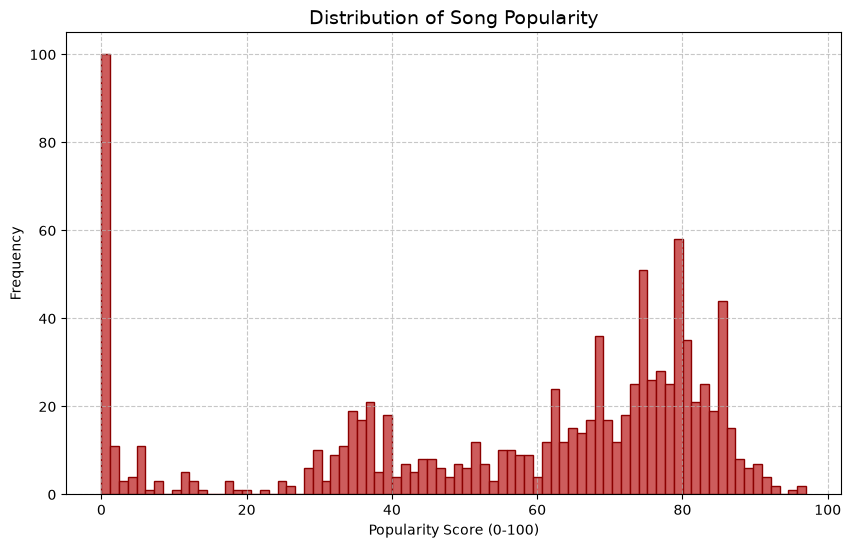

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['popularity'], bins=80, color='indianred', edgecolor='darkred')
plt.title('Distribution of Song Popularity', fontsize=14)
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


C:\Users\james\AppData\Local\Temp\ipykernel_9876\3615971948.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='year', y='popularity', data=df, palette='plasma')


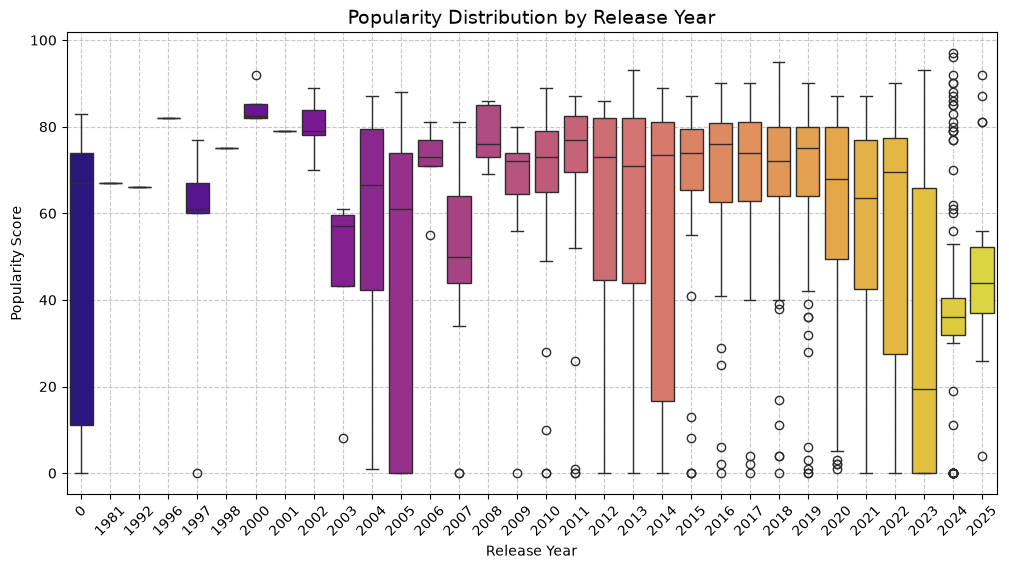

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.boxplot(x='year', y='popularity', data=df, palette='plasma')
plt.title('Popularity Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


C:\Users\james\AppData\Local\Temp\ipykernel_9876\2185356775.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


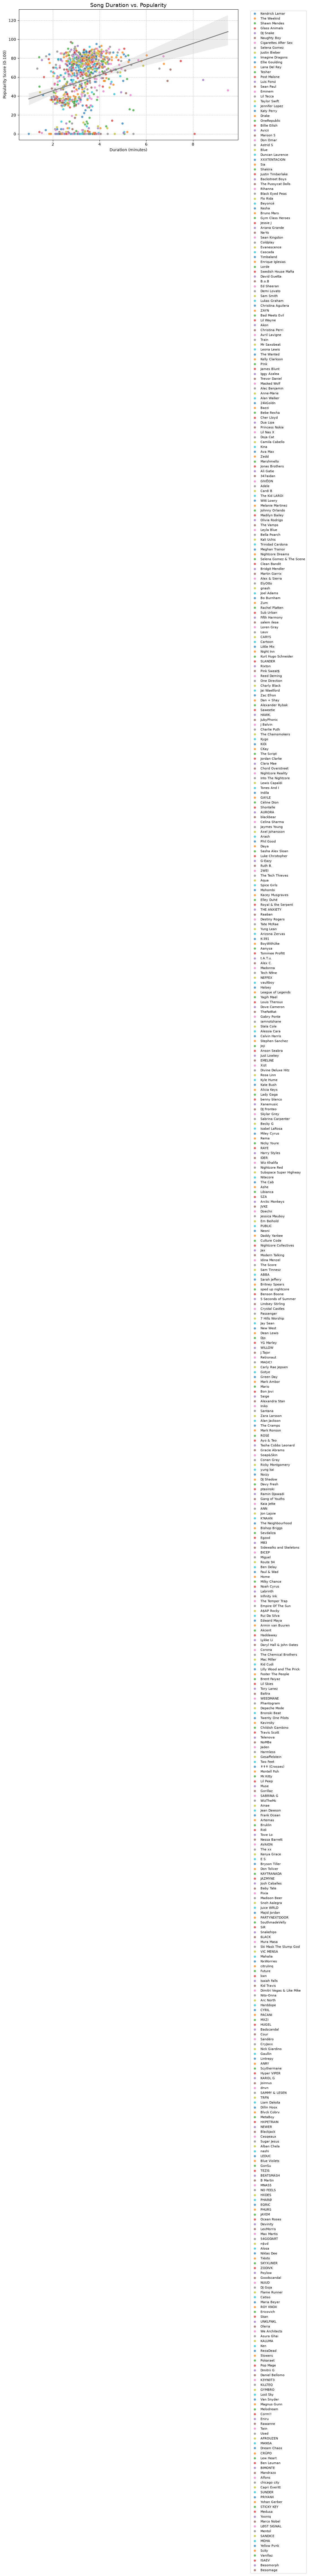

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='duration_min',
    y='popularity',
    hue='artist',
    data=df,
    alpha=0.7,
    palette='tab10',
)
sns.regplot(
    x='duration_min', y='popularity', data=df, scatter=False, color='grey'
)
plt.title('Song Duration vs. Popularity', fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score (0-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


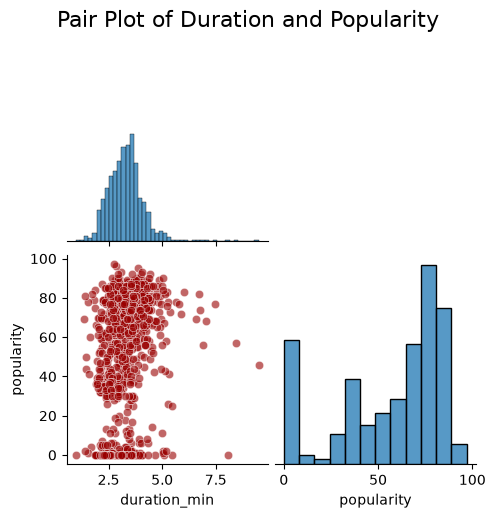

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

key_features = ['duration_min', 'popularity']
sns.pairplot(
    df[key_features],
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.6, 'color': '#990000'},
)
plt.suptitle('Pair Plot of Duration and Popularity', y=1.02, fontsize=16)
plt.show()


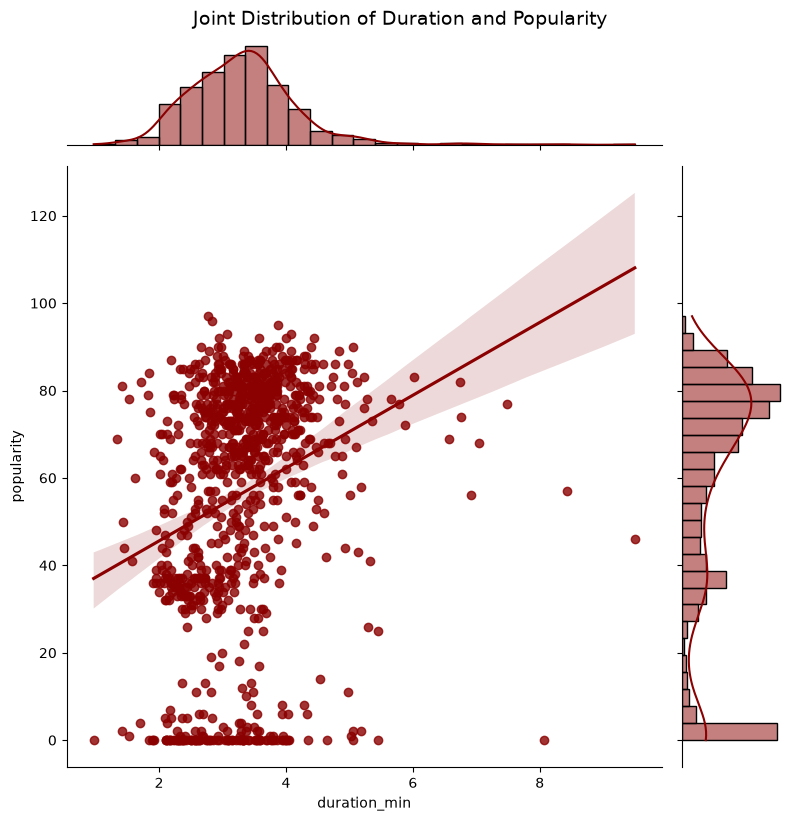

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

g = sns.jointplot(
    x='duration_min',
    y='popularity',
    data=df,
    kind='reg',
    height=8,
    color='darkred',
    marginal_kws={'bins': 25},
)
g.fig.suptitle('Joint Distribution of Duration and Popularity', y=1.02, fontsize=14)
plt.show()


In [22]:
crosstab = pd.crosstab(df['decade'], df['artist'])
top3 = df['artist'].value_counts().head(3).index
crosstab[top3].plot(kind='bar', stacked=True, colormap='coolwarm')
plt.title(f"{student_name} ({student_id})\nTop 3 Artists by Decade")
plt.ylabel('Number of Songs')
plt.show()


KeyError: 'decade'